In [1]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import matplotlib.pyplot as plt
from EDA_Funcions.eda_utils import gerar_resumo_colunas
from EDA_Funcions.eda_utils import calcular_potencia_ativa_total, COLS_POTENCIA
from EDA_Funcions.eda_utils import calcular_estatisticas_globais, COLS_POTENCIA
from EDA_Funcions.eda_utils import calcular_potencia_ativa_total
from EDA_Funcions.eda_graficos import preparar_dados_temporais, plotar_calendario_mensal, plotar_dias_sequenciais
from EDA_Funcions.eda_utils import calcular_potencia_ativa_total
from EDA_Funcions.eda_graficos import preparar_dados_temporais, plotar_calendario_mensal, plotar_dias_sequenciais
from EDA_Funcions.eda_graficos import preparar_dados_temporais, plotar_calendario_mensal
from EDA_Funcions.eda_utils import calcular_potencia_ativa_total


In [2]:
caminho_ccet = "/home/ls/TCC_2026/Dados greefra/mes_1/dados_limpos/Medidor_CCET.csv"
caminho_bio = "/home/ls/TCC_2026/Dados greefra/mes_1/dados_limpos/Medidor_BIO.csv"
caminho_cch = "/home/ls/TCC_2026/Dados greefra/mes_1/dados_limpos/Medidor_CCH.csv"
caminho_ccso = "/home/ls/TCC_2026/Dados greefra/mes_1/dados_limpos/Medidor_CCSO.csv"
caminho_iee = "/home/ls/TCC_2026/Dados greefra/mes_1/dados_limpos/Medidor_IEE.csv"
caminho_odonto = "/home/ls/TCC_2026/Dados greefra/mes_1/dados_limpos/Medidor_ODONTO.csv"
caminho_pf = "/home/ls/TCC_2026/Dados greefra/mes_1/dados_limpos/Medidor_PF.csv"

In [3]:
caminho = [caminho_bio, caminho_cch, caminho_ccso, caminho_iee, caminho_odonto, caminho_pf]

In [18]:
# Carrega os dados (agora sem erros de Parser)
df_ccet = pd.read_csv(caminho_ccet)

/tmp/ipykernel_2351/3213781868.py:2: DtypeWarning: Columns (0: network.wifi_mode, 1: network.type, 2: network.ssid, 3: network.status, 4: network.rssi.unit, 5: network.signal.unit, 6: network.ipv4.type, 7: network.ipv4.address, 8: network.ipv4.subnet_mask, 9: network.ipv4.gateway, 10: network.ipv4.dns1, 11: network.ipv4.dns2, 12: network.ipv6.address, 13: lastgasp) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ccet = pd.read_csv(caminho_ccet)


In [ ]:
# Exibe as primeiras 5 linhas para inspeção visual
display(df_ccet.head())

/tmp/ipykernel_2351/93589480.py:5: DtypeWarning: Columns (0: network.wifi_mode, 1: network.type, 2: network.ssid, 3: network.status, 4: network.rssi.unit, 5: network.signal.unit, 6: network.ipv4.type, 7: network.ipv4.address, 8: network.ipv4.subnet_mask, 9: network.ipv4.gateway, 10: network.ipv4.dns1, 11: network.ipv4.dns2, 12: network.ipv6.address, 13: lastgasp) have mixed types. Specify dtype option on import or set low_memory=False.
  df_ccet = pd.read_csv(caminho_ccet)


,id,server,item_name,sensor_type,location_description,timestamp_leitura_anterior,minutos_desde_ultima_leitura,flag_inatividade,horas_inativo,device.name,...,network.signal.value,network.signal.unit,network.ipv4.type,network.ipv4.address,network.ipv4.subnet_mask,network.ipv4.gateway,network.ipv4.dns1,network.ipv4.dns2,network.ipv6.address,lastgasp
0,341872,23299981,Medidor CCET,Energia,O medidor de energia está instalado na Subesta...,NaN,NaN,0,0.0,Telik Trafo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,341888,23299981,Medidor CCET,Energia,O medidor de energia está instalado na Subesta...,2025-08-01 00:00:02,5.0,0,0.0,Telik Trafo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,341906,23299981,Medidor CCET,Energia,O medidor de energia está instalado na Subesta...,2025-08-01 00:05:02,5.0,0,0.0,Telik Trafo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,341922,23299981,Medidor CCET,Energia,O medidor de energia está instalado na Subesta...,2025-08-01 00:10:02,5.0,0,0.0,Telik Trafo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,341939,23299981,Medidor CCET,Energia,O medidor de energia está instalado na Subesta...,2025-08-01 00:15:02,5.0,0,0.0,Telik Trafo,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- Resumo Técnico do DataFrame ---


In [3]:
# Libera o limite visual do Pandas para exibir todas as linhas na tela
pd.set_option('display.max_rows', 150)

# Chama a nova função e exibe a tabela completa
tabela_resumo = gerar_resumo_colunas(df_ccet)
display(tabela_resumo)

,Tipo de Dado,Valores Preenchidos,Valores Faltantes (NaN)
id,int64,97357,0
server,int64,97357,0
item_name,str,97357,0
sensor_type,str,97357,0
location_description,str,97357,0
timestamp_leitura_anterior,str,97341,16
minutos_desde_ultima_leitura,float64,97341,16
flag_inatividade,int64,97357,0
horas_inativo,float64,97357,0
device.name,str,97357,0


In [4]:
# Calcula a demanda instantânea total do prédio
df_ccet = calcular_potencia_ativa_total(df_ccet)

# Usa a constante importada para exibir exatamente as colunas que importam
display(df_ccet[COLS_POTENCIA].head())

⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!


,active_power.phase.a,active_power.phase.b,active_power.phase.c,active_power.total
0,17.127,8.904,11.981,38.012
1,13.799,8.141,12.197,34.137
2,17.229,11.415,12.723,41.367
3,16.111,8.932,12.181,37.224
4,15.662,9.263,11.793,36.718


In [5]:
# Chama a função passando a coluna que queremos investigar
estatisticas_potencia = calcular_estatisticas_globais(df_ccet, 'active_power.total')

# Exibe o resultado como uma tabela limpa
display(estatisticas_potencia)

📊 Estatísticas processadas para a coluna: 'active_power.total'


Mínimo (Min)          -65.326000
Máximo (Max)          352.326000
Média (Mean)           87.809089
Q1 (25%)               35.512000
Q2 / Mediana (50%)     43.801000
Q3 (75%)              122.940000
Percentil 95.0%       265.700400
Percentil 98.0%       295.817000
Percentil 99.0%       312.959000
Percentil 99.9%       337.981000
Name: Estatísticas Globais: active_power.total, dtype: float64

In [ ]:
# Importa as ferramentas e as DUAS funções de gráficos

# 1. Recalcula a Potência Total
df_ccet = calcular_potencia_ativa_total(df_ccet)

# 2. Trata os dados temporais e adiciona a coluna "dia_da_semana"
df_ccet = preparar_dados_temporais(df_ccet, coluna_tempo='timestamp_leitura_anterior')

# 3. Exibe algumas linhas para confirmar a nova coluna
display(df_ccet[['dia_da_semana', 'active_power.total']].head(3))

print("\nGerando visualização...")

# =========================================================
# 4. ÁREA DE PLOTAGEM (Escolha qual deseja ver)
# =========================================================

# Opção A: Visão Panorâmica (Matriz em Calendário)
# Tire o '#' da linha abaixo para rodar esta visualização
# plotar_calendario_mensal(df_ccet, ano=2025, mes=8, coluna='active_power.total')

# Opção B: Visão Detalhada (Gráficos Sequenciais Empilhados de 2 em 2 horas)
# Coloque um '#' na linha abaixo se preferir rodar apenas o calendário
plotar_dias_sequenciais(df_ccet, ano=2025, mes=8, coluna='active_power.total')

⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!
❌ Erro: Coluna 'timestamp_leitura_anterior' não encontrada.




In [16]:
# 1. Recalcula a Potência Total
df_ccet = calcular_potencia_ativa_total(df_ccet)

# 2. Trata os dados temporais e adiciona a coluna "dia_da_semana"
df_ccet = preparar_dados_temporais(df_ccet, coluna_tempo='timestamp_leitura_anterior')

plotar_dias_sequenciais(df_ccet, ano=2025, mes=8, coluna='active_power.total')

⚡ Coluna 'active_power.total' calculada e adicionada com sucesso!
✅ Dados temporais tratados. Coluna 'dia_da_semana' adicionada e índice configurado.


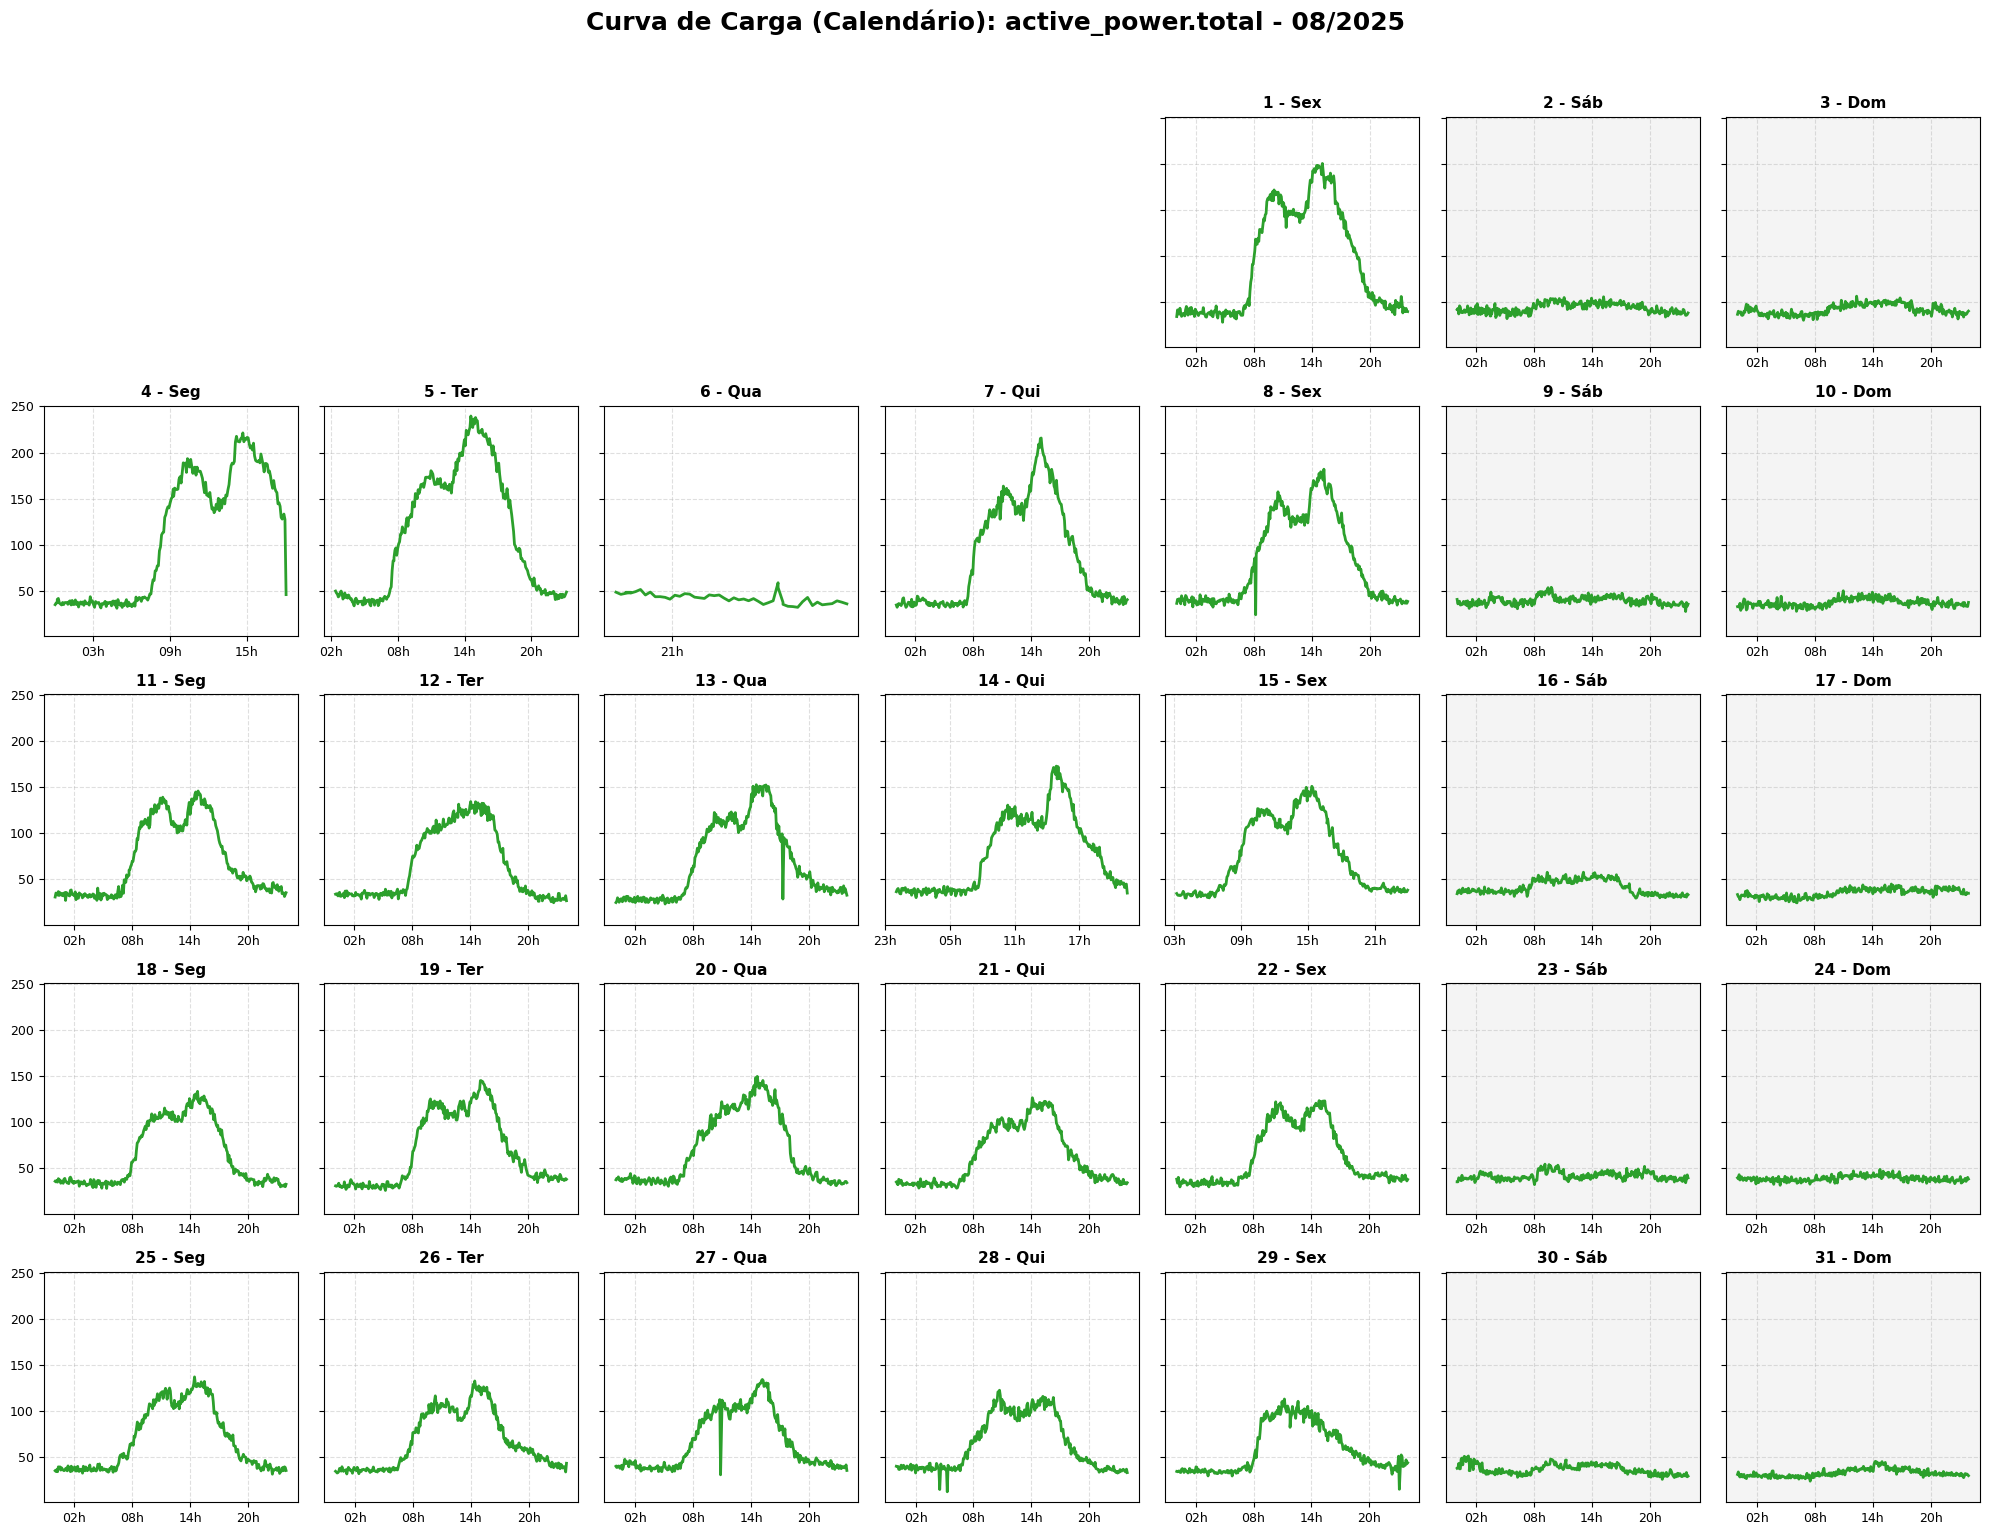

In [24]:

df_ccet = calcular_potencia_ativa_total(df_ccet)


df_ccet = preparar_dados_temporais(df_ccet, coluna_tempo='timestamp_leitura_anterior')

plotar_calendario_mensal(df_ccet, ano=2025, mes=8, coluna='active_power.total')

In [ ]:
def main():
    while True:
        for(caminho in caminho):
            df = pd.read_csv(caminho)
            df = calcular_potencia_ativa_total(df)
            df = preparar_dados_temporais(df, coluna_tempo='timestamp_leitura_anterior')

            for (plotar_calendario_mensal(df, ano=2025, mes=8, coluna='active_power.total'))
                

SyntaxError: invalid syntax (4083729854.py, line 3)